# Experiment 1: baseline confusion classifier (TF-IDF + Logistic Regression)

*J26-IT-304 PP1. Notebook 01, sections 1-2 (setup, load and inspect).*

## 1. Setup and provenance

**Objective.** Train a TF-IDF + Logistic Regression baseline that classifies a student's answer
text as *confused* / *understood*. This is a supervised, machine-learning-based text
classification task (IRWA Lecture 06). The pipeline is: text preprocessing, then feature
extraction (TF-IDF), then a classifier, evaluated with a validation-set approach.

**Important caveat.** "Confused" is a **proxy** built from the dataset's answer-correctness
label, not a direct measurement of confusion. The full caveat comes in section 5.

**Why this cell.** A result is only reproducible if we know exactly which library versions, seed
and dataset commit produced it. The scikit-learn version matters most, because the tutor service
must unpickle the final model under the same version. The dataset revision is a pinned commit
SHA, so a later run fetches exactly this data and not "latest".

In [1]:
import sys
import numpy as np
import pandas as pd
import sklearn
import huggingface_hub

from confusion_baseline import SEED
from confusion_baseline.data import DATASET_REPO, DATASET_REVISION, load_raw

print("python            :", sys.version.split()[0])
print("pandas            :", pd.__version__)
print("numpy             :", np.__version__)
print("scikit-learn      :", sklearn.__version__)
print("huggingface_hub   :", huggingface_hub.__version__)
print("SEED              :", SEED)
print("DATASET_REPO      :", DATASET_REPO)
print("DATASET_REVISION  :", DATASET_REVISION)

python            : 3.13.16
pandas            : 3.0.6
numpy             : 2.5.4
scikit-learn      : 1.9.1
huggingface_hub   : 2.2.0
SEED              : 42
DATASET_REPO      : nitinnovtech-ai-space/JavaQuestionSynthFinal
DATASET_REVISION  : e29cfdd4ec4179f54b2ea0409329207104de8bed


## 2. Load and inspect

**Why this cell.** `load_raw()` is the single entry point to the data, shared with the training
script so notebook and script cannot drift. It assigns `row_id` (position in the raw file, the
stable key for all later units) before anything else, and it moves every `FollowUp`-derived
column into a separate `followup_quarantine` frame. The tutor-feedback text in `FollowUp`
reveals the label, so the working frame must never contain it. The quarantine lets a later
unit show one example of the leak without the leak ever being in `df`.

In [2]:
df, followup_quarantine, load_report = load_raw()

print("raw file format :", load_report["format"], load_report["files"])
print("shape           :", df.shape)
print("columns         :", list(df.columns))
print()
print("dtypes:")
print(df.dtypes.to_string())

raw file format : parquet ['data/train-00000-of-00001.parquet']
shape           : (1078, 4)
columns         : ['row_id', 'Question', 'Answer', 'Correctness']

dtypes:
row_id         int64
Question         str
Answer           str
Correctness      str


**Why this cell.** First look at the records, and a count of missing values per column. Empty
or null answers would need a decision in the cleaning unit, so we want to know now whether any exist.

In [3]:
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
display(df.head(5))
print("missing values per column:")
print(df.isna().sum().to_string())

,row_id,Question,Answer,Correctness
0,0,What is the difference between an abstract class and an interface in Java?,"An abstract class can have both abstract methods and concrete methods, where...",Correct
1,1,What is the difference between an abstract class and an interface in Java?,Abstract classes are used to provide common functionality for all subclasses...,Partial Correct
2,2,What is the difference between an abstract class and an interface in Java?,An abstract class is used for defining blueprints and can contain both imple...,Wrong
3,3,Explain the concept of exception handling in Java.,Exception handling in Java is done using try-catch blocks. If an exception i...,Correct
4,4,Explain the concept of exception handling in Java.,"Java exceptions are for catching errors like in runtime, and it uses catch b...",Partial Correct


missing values per column:
row_id         0
Question       0
Answer         0
Correctness    0


**Why this cell.** Exact duplicates can leak between train and validation splits and inflate the
score. Two counts are printed on purpose, because they answer different questions: the working
frame has no `FollowUp` columns, so rows that differ only in their follow-up text look identical
there. The count on the full raw record (computed inside `load_raw()`, where `FollowUp` is still
present) tells us how many of those are true duplicates.

In [4]:
dup_working = int(df.drop(columns="row_id").duplicated().sum())
dup_full = load_report["duplicates_full_record_incl_followup"]
print("exact duplicates, WORKING frame (all columns except row_id, no FollowUp):", dup_working)
print("exact duplicates, FULL raw record (INCLUDING FollowUp)                  :", dup_full)

exact duplicates, WORKING frame (all columns except row_id, no FollowUp): 2
exact duplicates, FULL raw record (INCLUDING FollowUp)                  : 2


**Why this cell.** A schema check on the label column only. `repr()` makes stray whitespace or
case variants visible, which would silently create extra classes. This prints raw strings only;
the distribution analysis is the next unit.

In [5]:
for value, n in df["Correctness"].value_counts(dropna=False).items():
    print(f"{value!r:20} {n}")

'Correct'            422
'Wrong'              367
'Partial Correct'    289


**Why this cell.** The spec's description of the dataset is second-hand. This table puts what the
spec says next to what was actually found, so any correction is explicit and evidenced.

In [6]:
spec_labels = {"Correct", "Partial Correct", "Wrong"}
found_labels = set(df["Correctness"].dropna().unique())
fu_cols = load_report["followup_columns_raw"]
fu_struct = load_report["followup_structure"]
fu_keys = [c for c in followup_quarantine.columns if c != "row_id"]

def row(item, spec, found, ok):
    return {"item": item, "spec says": spec, "found": found, "match": "yes" if ok else "no"}

schema = pd.DataFrame([
    row("row count", "~1,078", len(df), 1000 <= len(df) <= 1150),
    row("Question", "column present", f"present, dtype {df['Question'].dtype}" if "Question" in df else "absent", "Question" in df),
    row("Answer", "column present", f"present, dtype {df['Answer'].dtype}" if "Answer" in df else "absent", "Answer" in df),
    row("Correctness", "column present", f"present, dtype {df['Correctness'].dtype}" if "Correctness" in df else "absent", "Correctness" in df),
    row("Correctness values", sorted(spec_labels), sorted(found_labels), found_labels == spec_labels),
    row("FollowUp Part1", "field present", f"{fu_cols} ({fu_struct}) -> {'followup_Part1' in fu_keys}", "followup_Part1" in fu_keys),
    row("FollowUp Part2", "field present", f"{fu_cols} ({fu_struct}) -> {'followup_Part2' in fu_keys}", "followup_Part2" in fu_keys),
])
display(schema)

,item,spec says,found,match
0,row count,"~1,078",1078,yes
1,Question,column present,"present, dtype str",yes
2,Answer,column present,"present, dtype str",yes
3,Correctness,column present,"present, dtype str",yes
4,Correctness values,"[Correct, Partial Correct, Wrong]","[Correct, Partial Correct, Wrong]",yes
5,FollowUp Part1,field present,['FollowUp Question'] ({'FollowUp Question': 'dict'}) -> True,yes
6,FollowUp Part2,field present,['FollowUp Question'] ({'FollowUp Question': 'dict'}) -> True,yes


**Why this cell.** Shape and column names of the quarantine only. Its contents are deliberately
not printed here; the leakage demonstration belongs to the next unit.

In [7]:
print("followup_quarantine shape  :", followup_quarantine.shape)
print("followup_quarantine columns:", list(followup_quarantine.columns))

followup_quarantine shape  : (1078, 3)
followup_quarantine columns: ['row_id', 'followup_Part1', 'followup_Part2']


**Why this cell.** A hard guarantee instead of a promise: if any `FollowUp`-derived column is in
the working frame, the notebook stops here.

In [8]:
leaked = [c for c in df.columns if 'follow' in c.lower()]
assert not leaked, leaked
print("PASS: no FollowUp-derived column in the working frame:", list(df.columns))

PASS: no FollowUp-derived column in the working frame: ['row_id', 'Question', 'Answer', 'Correctness']


## 3. Exploratory data analysis

EDA here is evidence, not decoration: every cleaning decision in the next unit must follow from
something printed in this section, and section 3.8 lists those decisions with the subsection that
justifies each. Nothing in this section modifies `df`; no labels are mapped, no split is made and no
model is trained. Figures are saved to `reports/experiments/` at dpi=200.

**Why this cell.** Shared imports and a figure helper, so every figure is saved the same way
(PNG, dpi=200, readable on a projector) and also shown inline.

In [9]:
import re
from collections import Counter

import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.metrics.pairwise import cosine_similarity

from confusion_baseline import REPORTS_DIR
from confusion_baseline.text import normalize_key

FIG_DIR = REPORTS_DIR / "experiments"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CLASSES = ["Correct", "Partial Correct", "Wrong"]
COLORS = ["#4c78a8", "#f2a33a", "#c0504d"]
plt.rcParams.update({"font.size": 11})

def save_fig(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("saved:", path.relative_to(FIG_DIR.parent.parent).as_posix())
    plt.show()

### 3.1 Label distribution

**Why.** The class balance decides whether `class_weight='balanced'` is needed and sets the floor
that any model must beat. Below the table is a *preview* of the binary target the primary mapping
would give (Correct -> understood; Partial Correct + Wrong -> confused). The preview does not modify `df`.

,count,proportion
Correctness,,
Correct,422,0.3915
Partial Correct,289,0.2681
Wrong,367,0.3404


saved: reports/experiments/eda_label_distribution.png


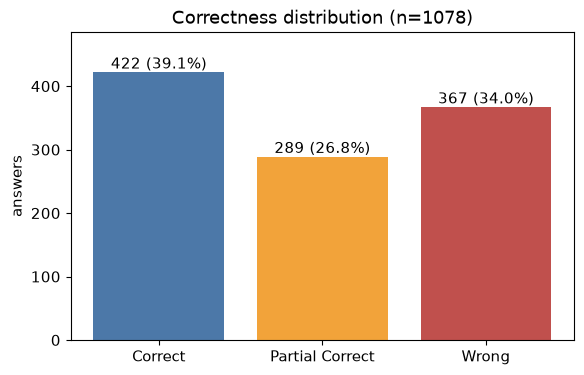


PREVIEW of the primary mapping (df is not modified):
  p(confused)   = 0.6085   p(understood) = 0.3915   ratio = 1.55 : 1
  F1(confused) of a constant 'always confused' predictor = 2p/(1+p) = 0.7566


In [10]:
counts = df["Correctness"].value_counts().reindex(CLASSES)
display(pd.DataFrame({"count": counts, "proportion": (counts / len(df)).round(4)}))

fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(CLASSES, counts.values, color=COLORS)
ax.bar_label(bars, labels=[f"{c} ({c / len(df):.1%})" for c in counts.values])
ax.set_ylabel("answers")
ax.set_ylim(0, counts.max() * 1.15)
ax.set_title(f"Correctness distribution (n={len(df)})")
save_fig(fig, "eda_label_distribution.png")

p = float((df["Correctness"] != "Correct").mean())
print()
print("PREVIEW of the primary mapping (df is not modified):")
print(f"  p(confused)   = {p:.4f}   p(understood) = {1 - p:.4f}   ratio = {p / (1 - p):.2f} : 1")
print(f"  F1(confused) of a constant 'always confused' predictor = 2p/(1+p) = {2 * p / (1 + p):.4f}")

**Reading 3.1.** Under the preview mapping 60.9% of answers are *confused* and 39.1% *understood*
(1.55 : 1). A constant "always confused" predictor already reaches F1(confused) = 0.757, so that is the
floor any model must clearly beat; accuracy alone would be a misleading headline. The imbalance is mild,
so `class_weight='balanced'` is not obviously required. It is cheap to test, and 3.8 treats it as a
hyperparameter to compare on the validation set instead of assuming it.

### 3.2 Question grouping

**Why.** Each question has several answers. If answers to the same question land on both sides of
a train/validation split, the model can score well by recognising the *question's topic* instead of
judging the *answer*. The numbers here are the evidence for splitting by group.

In [11]:
qn = df["Question"].map(normalize_key)
print("unique Question strings (raw)       :", df["Question"].nunique())
print("unique Question after normalisation :", qn.nunique())

coll = df.assign(qn=qn).groupby("qn")["Question"].agg(lambda s: sorted(set(s)))
coll = coll[coll.map(len) > 1]
print("normalisation collisions (several raw strings share one normalised form):", len(coll))
for k, v in coll.items():
    print("  ", repr(k), "<-", v)

unique Question strings (raw)       : 360
unique Question after normalisation : 360
normalisation collisions (several raw strings share one normalised form): 0


,n questions
answers per question,
1,5
2,79
3,244
4,15
5,3
6,6
7,3
9,2
10,1


count    360.00
mean       2.99
std        1.17
min        1.00
25%        3.00
50%        3.00
75%        3.00
max       12.00
saved: reports/experiments/eda_answers_per_question.png


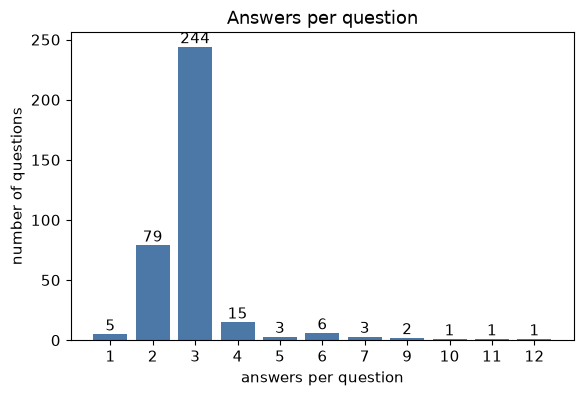

In [12]:
per_q = df.groupby("Question").size()
dist = per_q.value_counts().sort_index().rename_axis("answers per question").rename("n questions").to_frame()
display(dist)
print(per_q.describe().round(2).to_string())

fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(dist.index.astype(str), dist["n questions"], color="#4c78a8")
ax.bar_label(bars)
ax.set_xlabel("answers per question")
ax.set_ylabel("number of questions")
ax.set_title("Answers per question")
save_fig(fig, "eda_answers_per_question.png")

In [13]:
blocks = {}
for q, ids in df.groupby("Question")["row_id"].apply(list).items():
    ids = sorted(ids)
    blocks[q] = (1 + sum(b - a > 1 for a, b in zip(ids, ids[1:])), ids)
recur = {q: v for q, v in blocks.items() if v[0] > 1}
print("questions stored as ONE contiguous block of rows:", sum(v[0] == 1 for v in blocks.values()), "of", len(blocks))
print("questions that recur in separate blocks         :", len(recur))
for q, (nb_, ids) in list(recur.items())[:2]:
    print(f"  e.g. {q!r}\n       {nb_} blocks, row_ids {ids}")

comp = (df.groupby("Question")["Correctness"].value_counts().unstack(fill_value=0)
        .reindex(columns=CLASSES, fill_value=0))
comp.columns = ["n_Correct", "n_Partial", "n_Wrong"]
print()
print("label composition per question (rows = a combination of per-class answer counts):")
display(comp.value_counts().rename("n questions").to_frame().head(12))
print("distinct combinations:", comp.drop_duplicates().shape[0], "(top 12 shown)")
print("questions with all three classes present      :", int((comp > 0).all(axis=1).sum()), "of", len(comp))
print("questions with Correct + at least one other   :", int(((comp["n_Correct"] > 0) & (comp[["n_Partial", "n_Wrong"]].sum(axis=1) > 0)).sum()))
print("questions with a single class only            :", int(((comp > 0).sum(axis=1) == 1).sum()),
      "->", comp[(comp > 0).sum(axis=1) == 1].sum().to_dict())

questions stored as ONE contiguous block of rows: 345 of 360
questions that recur in separate blocks         : 15
  e.g. 'How would you write a Java program to check if a number is prime?'
       2 blocks, row_ids [770, 771, 772, 773, 776, 777, 778, 779, 780]
  e.g. 'What is a constructor in Java?'
       2 blocks, row_ids [27, 28, 29, 60, 61, 62]



label composition per question (rows = a combination of per-class answer counts):


n questions
n_Correct n_Partial n_Wrong             
1         1         1                213
          0         1                 65
2         0         1                 13
          1         1                 12
1         0         2                 10
          1         0                  9
2         2         2                  6
1         0         0                  5
0         1         1                  4
2         1         0                  4
1         2         0                  3
3         2         2                  3

distinct combinations: 23 (top 12 shown)
questions with all three classes present      : 242 of 360
questions with Correct + at least one other   : 349
questions with a single class only            : 7 -> {'n_Correct': 10, 'n_Partial': 0, 'n_Wrong': 0}


In [14]:
# Evidence for the group split: how much a plain random 80/20 split would leak.
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(df))
n_val = int(round(0.2 * len(df)))
val_q = df["Question"].iloc[perm[:n_val]]
train_q = set(df["Question"].iloc[perm[n_val:]])
share = float(np.mean([q in train_q for q in val_q]))
print(f"random 80/20 split (seed {SEED}): {share:.1%} of validation rows have their Question in the training half")

random 80/20 split (seed 42): 93.5% of validation rows have their Question in the training half


**Why a random split would leak.** There are 360 distinct questions for 1,078 answers, and 244 of
them have exactly three answers (the mode, not a rule: 5 questions have one answer, 79 have two, and 32
have four or more, up to 12). Normalising the question text changes nothing (360 before and after, no
collisions). Most questions carry several labels (see the composition table), so the *topic* of a
question is shared by rows of different classes. In a plain random 80/20 split, 93.5% of validation
rows have their exact Question in the training half, so a model can partly score by recognising a
question's vocabulary instead of judging the answer. A split must keep all rows of one question on the
same side. Also, 15 questions recur in *separate blocks* of the file (e.g. the prime-number question
spans rows 770-780 in two blocks), so keeping contiguous file ranges together is not enough: the
grouping has to be by the Question string, not by position.

### 3.3 Duplicates and overlap

**Why.** Exact duplicates can sit on both sides of a split and inflate the score; a label conflict
(same text, different label) is label noise we can see directly; the same answer under *different*
questions is a leak that a group split by Question does not catch. Near-duplicates are checked with
TF-IDF cosine similarity. Fitting a vectoriser on all rows is acceptable **here only**, because this
is a descriptive check and never a feature set for a model.

In [15]:
KEY = ["Question", "Answer", "Correctness"]
dup_mask = df.duplicated(subset=KEY, keep=False)
rec_sizes = df[dup_mask].groupby(KEY).size()
print("rows involved in exact duplicates :", int(dup_mask.sum()))
print("records that have copies          :", len(rec_sizes))
print("copies per record                 :", {int(k): int(v) for k, v in rec_sizes.value_counts().items()})
print("surplus rows (would be dropped)   :", int(df.duplicated(subset=KEY).sum()))
for i, (k, g) in enumerate(df[dup_mask].groupby(KEY, sort=False), 1):
    print(f"\nrecord {i}: row_ids {g['row_id'].tolist()}")
    print(f"  Question   : {k[0]}")
    print(f"  Answer     : {k[1]}")
    print(f"  Correctness: {k[2]}")

rows involved in exact duplicates : 3
records that have copies          : 1
copies per record                 : {3: 1}
surplus rows (would be dropped)   : 2

record 1: row_ids [0, 15, 1060]
  Question   : What is the difference between an abstract class and an interface in Java?
  Answer     : An abstract class can have both abstract methods and concrete methods, whereas an interface can only have abstract methods unless it's a default method.
  Correctness: Correct


In [16]:
nl = df.groupby(["Question", "Answer"])["Correctness"].nunique()
conf = nl[nl > 1]
print("(Question, Answer) pairs with conflicting Correctness:", len(conf))
for q, a in conf.index:
    sub = df[(df["Question"] == q) & (df["Answer"] == a)]
    print(f"  Q: {q}\n  A: {a}\n  rows/labels: {list(zip(sub['row_id'], sub['Correctness']))}")

(Question, Answer) pairs with conflicting Correctness: 0


In [17]:
def cross_question(key, label, show=15):
    g = df.assign(key=key).groupby("key").agg(
        n_q=("Question", "nunique"), row_ids=("row_id", list),
        labels=("Correctness", list), questions=("Question", lambda s: sorted(set(s))))
    g = g[g["n_q"] > 1]
    print(f"{label}: {len(g)} answer texts appear under more than one Question "
          f"({int(g['row_ids'].map(len).sum())} rows)")
    for k, r in list(g.iterrows())[:show]:
        print(f"  row_ids {r['row_ids']}  labels {r['labels']}")
        print(f"    answer   : {k[:140]}")
        for q in r["questions"]:
            print(f"    question : {q}")
    if len(g) > show:
        print(f"  ... {len(g) - show} more groups not shown")
    return g

same_exact = cross_question(df["Answer"], "EXACT same Answer under different Questions")
print()
same_norm = cross_question(df["Answer"].map(normalize_key), "NORMALISED same Answer under different Questions")

EXACT same Answer under different Questions: 0 answer texts appear under more than one Question (0 rows)

NORMALISED same Answer under different Questions: 0 answer texts appear under more than one Question (0 rows)


In [18]:
# Descriptive only: this vectoriser is fitted on all rows and is never a model feature.
X_desc = TfidfVectorizer().fit_transform(df["Answer"])
S = cosine_similarity(X_desc)
iu, ju = np.triu_indices_from(S, k=1)
sim = S[iu, ju]
hit = sim >= 0.90
iu, ju, sim = iu[hit], ju[hit], sim[hit]
other_q = qn.values[iu] != qn.values[ju]
iu, ju, sim = iu[other_q], ju[other_q], sim[other_q]
same_text = (df["Answer"].map(normalize_key).values[iu] == df["Answer"].map(normalize_key).values[ju])

print("answer pairs with TF-IDF cosine >= 0.90 and DIFFERENT Questions:", len(sim))
print("  of which the normalised answer text is identical               :", int(same_text.sum()))
print("  of which the text differs (true near-duplicates)               :", int((~same_text).sum()))
order = np.argsort(-sim[~same_text], kind="stable")[:10]
ii, jj, ss = iu[~same_text][order], ju[~same_text][order], sim[~same_text][order]
print("\nup to 10 near-duplicate (non-identical) pairs, highest cosine first:")
for a, b, s_ in zip(ii, jj, ss):
    print(f"  cos={s_:.3f}  row {df['row_id'].iloc[a]} [{df['Correctness'].iloc[a]}] vs row {df['row_id'].iloc[b]} [{df['Correctness'].iloc[b]}]")
    print(f"    Q1: {df['Question'].iloc[a]}\n    A1: {df['Answer'].iloc[a][:160]}")
    print(f"    Q2: {df['Question'].iloc[b]}\n    A2: {df['Answer'].iloc[b][:160]}")

answer pairs with TF-IDF cosine >= 0.90 and DIFFERENT Questions: 2
  of which the normalised answer text is identical               : 0
  of which the text differs (true near-duplicates)               : 2



up to 10 near-duplicate (non-identical) pairs, highest cosine first:
  cos=0.931  row 1028 [Correct] vs row 1033 [Correct]
    Q1: What does the `floor()` method do in Java?
    A1: The `floor()` method rounds a decimal number down to the nearest integer.
    Q2: How does `floor()` behave with positive decimal numbers in Java?
    A2: The `floor()` method rounds a positive decimal number down to the nearest integer.
  cos=0.901  row 920 [Wrong] vs row 932 [Correct]
    Q1: What is the return type of the `compareTo()` method?
    A1: The return type of `compareTo()` is a `boolean`, indicating whether two objects are equal or not.
    Q2: What is the return type of the `equals()` method in Java?
    A2: The return type of `equals()` is `boolean`, indicating whether two objects are equal or not.


**Reading 3.3.** One record is duplicated three times (row_ids 0, 15 and 1060), which leaves two
surplus rows; no other exact duplicates exist. There are no label conflicts, and no identical answer
text appears under different questions, exact or normalised. Only two cross-question near-duplicate
pairs reach cosine 0.90 (the `floor()` pair, rows 1028/1033, both Correct, and a `compareTo()` /
`equals()` pair, rows 920/932, Wrong vs Correct). Neither is a duplicate in the exact sense, but they show that
question *families* (e.g. `floor()`, `ceil()`, `rint()`) share wording, which a split by exact Question does
not separate. The effect is small here (two pairs) and is accepted and documented, not fixed.

### 3.4 Text statistics

**Why.** If confused answers are systematically shorter or longer, answer length alone carries
signal. A model could then look good by counting words, and later feature inspection has to be read
with that in mind. The length-only AUC (descriptive, no model) quantifies it under the preview mapping.

Correctness     Correct  Partial Correct  Wrong
n_chars  count    422.0            289.0  367.0
         mean     131.3            113.0   96.6
         std       32.1             24.5   23.5
         min       44.0             52.0   40.0
         25%      109.0             95.0   79.0
         50%      131.0            112.0   97.0
         75%      152.0            129.0  112.0
         max      230.0            192.0  179.0
n_tokens count    422.0            289.0  367.0
         mean      21.6             18.9   16.2
         std        5.4              4.2    4.2
         min        8.0              9.0    7.0
         25%       18.0             16.0   13.0
         50%       22.0             19.0   16.0
         75%       25.0             21.0   19.0
         max       36.0             31.0   32.0

saved: reports/experiments/eda_length_by_class.png


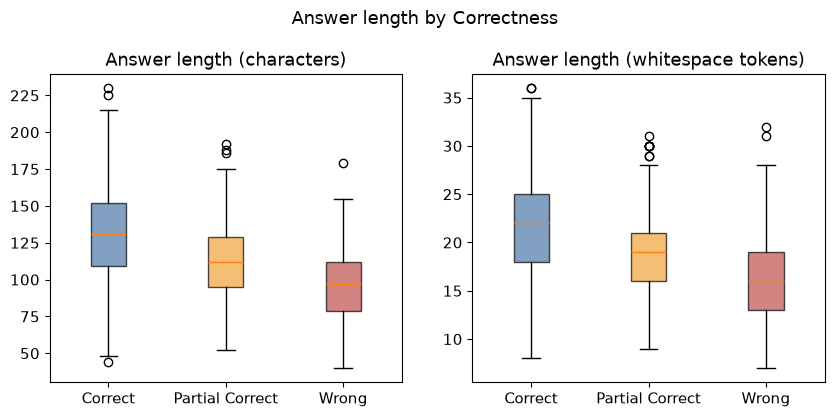


Length-only ROC AUC for confused vs understood (preview mapping, descriptive, no model):
  n_tokens : AUC = 0.2722   (AUC<0.5 means confused answers are SHORTER; strength = 0.7278)
  n_chars  : AUC = 0.2496   (AUC<0.5 means confused answers are SHORTER; strength = 0.7504)
median n_tokens: understood = 22.0 | confused = 17.0


In [19]:
stats = pd.DataFrame({
    "Correctness": df["Correctness"],
    "n_chars": df["Answer"].str.len(),
    "n_tokens": df["Answer"].str.split().str.len(),
})
desc = stats.groupby("Correctness")[["n_chars", "n_tokens"]].describe().reindex(CLASSES).round(1)
display(desc.T)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col, title in zip(axes, ["n_chars", "n_tokens"], ["Answer length (characters)", "Answer length (whitespace tokens)"]):
    data = [stats.loc[stats["Correctness"] == c, col] for c in CLASSES]
    bp = ax.boxplot(data, tick_labels=CLASSES, patch_artist=True)
    for patch, colr in zip(bp["boxes"], COLORS):
        patch.set_facecolor(colr)
        patch.set_alpha(0.7)
    ax.set_title(title)
fig.suptitle("Answer length by Correctness", y=1.04)
save_fig(fig, "eda_length_by_class.png")

y_conf = (df["Correctness"] != "Correct").astype(int)
print()
print("Length-only ROC AUC for confused vs understood (preview mapping, descriptive, no model):")
for col in ["n_tokens", "n_chars"]:
    auc = roc_auc_score(y_conf, stats[col])
    print(f"  {col:9s}: AUC = {auc:.4f}   (AUC<0.5 means confused answers are SHORTER; strength = {max(auc, 1 - auc):.4f})")
print("median n_tokens: understood =", stats.loc[y_conf == 0, "n_tokens"].median(),
      "| confused =", stats.loc[y_conf == 1, "n_tokens"].median())

**Reading 3.4.** Length separates the classes clearly. Median answer length is 22 tokens for Correct,
19 for Partial Correct and 16 for Wrong; confused answers (Partial + Wrong, median 17) are
systematically **shorter** than understood answers. Length alone gives ROC AUC 0.728 (tokens) and
0.750 (characters) in the "shorter = confused" direction (the printed AUC of 0.27 / 0.25 is the same number
flipped, because the positive class is confused). A model can therefore look good by counting words.
One caution for later: TF-IDF vectors are L2-normalised per document, which removes much of the length
information, so a plain TF-IDF model may not see this signal at all while a length-only baseline does.

### 3.5 Vocabulary and surface form

**Why.** Top terms show what the answers talk about; the *over-represented* terms show what separates
the classes (smoothed log-odds, defined below). The surface-form markers are where generator artefacts
show up (templated openings, punctuation style), and the later feature inspection is judged against this
baseline. Stop words are removed with sklearn's `ENGLISH_STOP_WORDS`; the vectoriser here is
descriptive only.

In [20]:
cv = CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS))
Xc = cv.fit_transform(df["Answer"])
vocab = np.array(cv.get_feature_names_out())
tot = np.asarray(Xc.sum(axis=0)).ravel()
per = {c: np.asarray(Xc[(df["Correctness"] == c).values].sum(axis=0)).ravel() for c in CLASSES}

def top_terms(arr, k):
    order = np.lexsort((vocab, -arr))[:k]      # ties broken alphabetically
    return [f"{vocab[i]} ({arr[i]})" for i in order]

top20 = pd.DataFrame({"overall": top_terms(tot, 20), **{c: top_terms(per[c], 20) for c in CLASSES}})
top20.index = range(1, 21)
print("Top 20 terms (term (count)), stop words removed:")
display(top20)

Top 20 terms (term (count)), stop words removed:


,overall,Correct,Partial Correct,Wrong
1,method (326),method (147),method (83),method (96)
2,java (257),class (123),class (63),java (86)
3,class (248),java (116),used (63),used (86)
4,used (226),used (77),java (55),class (62)
5,methods (139),object (62),methods (37),objects (43)
6,objects (134),methods (61),objects (35),program (43)
7,object (127),objects (56),object (32),methods (41)
8,value (108),value (50),classes (28),object (33)
9,memory (95),code (45),program (27),type (33)
10,code (93),memory (45),value (27),value (31)


In [21]:
# Smoothed log-odds of a term in class c versus the other two classes combined.
# log-odds(c vs rest) = log[(n_c + a) / (N_c + a*V)] - log[(n_r + a) / (N_r + a*V)],  a = 0.5,
# restricted to terms with total count >= 5 so one-off words do not dominate.
alpha, V = 0.5, len(vocab)
keep = tot >= 5
over = {}
for c in CLASSES:
    n_c, n_r = per[c], tot - per[c]
    lo = np.log((n_c + alpha) / (n_c.sum() + alpha * V)) - np.log((n_r + alpha) / (n_r.sum() + alpha * V))
    lo = np.where(keep, lo, -np.inf)
    order = np.lexsort((vocab, -lo))[:15]
    over[c] = [f"{vocab[i]} ({lo[i]:+.2f}; {n_c[i]}/{tot[i]})" for i in order]
over = pd.DataFrame(over)
over.index = range(1, 16)
print("15 most over-represented terms per class: term (log-odds; count in class / total count)")
display(over)

15 most over-represented terms per class: term (log-odds; count in class / total count)


,Correct,Partial Correct,Wrong
1,dynamic (+2.89; 7/7),constant (+1.99; 4/5),depending (+1.88; 4/5)
2,according (+2.58; 5/5),ensuring (+1.99; 4/5),names (+1.88; 4/5)
3,avoid (+2.58; 5/5),removing (+1.51; 6/9),programmer (+1.88; 4/5)
4,considered (+2.58; 5/5),implements (+1.48; 4/6),represent (+1.88; 4/5)
5,known (+2.58; 5/5),adding (+1.23; 3/5),similar (+1.88; 4/5)
6,root (+2.58; 5/5),common (+1.23; 3/5),syntax (+1.88; 4/5)
7,components (+1.65; 6/7),equality (+1.23; 3/5),global (+1.37; 4/6)
8,unless (+1.65; 6/7),share (+1.23; 3/5),size (+1.37; 4/6)
9,actual (+1.52; 9/11),subclassed (+1.23; 3/5),just (+1.32; 9/14)
10,contents (+1.48; 5/6),don (+1.20; 7/12),initialization (+1.23; 5/8)


In [22]:
A = df["Answer"]
markers = pd.DataFrame({
    "contains backtick `": A.str.contains("`", regex=False),
    "contains code fence ```": A.str.contains("```", regex=False),
    "Java-like token (; { ())": A.str.contains(r";|\{|\(\)", regex=True),
    "contains newline": A.str.contains("\n", regex=False),
    "hedging (maybe/I think/not sure/probably)": A.str.contains(r"\b(?:maybe|i think|not sure|probably)\b", case=False, regex=True),
    "curly quote/apostrophe (U+2018/2019/201C/201D)": A.str.contains("[\u2018\u2019\u201c\u201d]", regex=True),
    "any non-ASCII character": A.map(lambda t: not t.isascii()),
})
marker_table = markers.groupby(df["Correctness"]).mean().reindex(CLASSES).T.round(3)
marker_table["n answers (all)"] = markers.sum().astype(int)
print("Surface-form markers: proportion of answers per class")
display(marker_table)

opens = A.str.lower().str.split().str[:3].str.join(" ")
op = {c: [f"{t} ({n})" for t, n in Counter(opens[df["Correctness"] == c]).most_common(10)] for c in CLASSES}
op = pd.DataFrame(op)
op.index = range(1, 11)
print("\n10 most common opening three tokens per class:")
display(op)

Surface-form markers: proportion of answers per class


Correctness,Correct,Partial Correct,Wrong,n answers (all)
contains backtick `,0.514,0.460,0.488,529
contains code fence ```,0.000,0.000,0.000,0
Java-like token (; { ()),0.225,0.156,0.213,218
contains newline,0.000,0.000,0.000,0
hedging (maybe/I think/not sure/probably),0.000,0.000,0.000,0
curly quote/apostrophe (U+2018/2019/201C/201D),0.036,0.073,0.082,66
any non-ASCII character,0.036,0.073,0.082,66



10 most common opening three tokens per class:


,Correct,Partial Correct,Wrong
1,"yes, you can (11)",you can use (6),"yes, you can (9)"
2,you can use (6),"yes, you can (5)",the program will (8)
3,the `floor()` method (6),a constructor is (4),the time complexity (7)
4,the jit compiler (5),the `floor()` method (4),the return type (7)
5,the `rint()` method (5),the `static` keyword (3),the `floor()` method (6)
6,an abstract class (4),the jit compiler (3),the default value (5)
7,a constructor is (4),the ternary operator (3),the `rint()` method (5)
8,the default value (4),the `final` keyword (3),a constructor is (4)
9,the time complexity (4),the program will (3),the jit compiler (4)
10,the return type (4),abstract classes are (2),the `compareto()` method (4)


**Reading 3.5.**
- **Vocabulary is not strongly separating.** The overall top terms are Java vocabulary (method, class,
  java, used, object) and the class lists are nearly the same words in a slightly different order. The
  most over-represented terms per class are rare (counts 4-17), so the lexical signal is weak and noisy;
  e.g. `dynamic`, `according`, `avoid`, `known` lean Correct, and `depending`, `names`, `syntax` lean Wrong,
  but each rests on 5-7 occurrences. Default sklearn tokenisation also splits "don't" into `don`.
- **Code.** No answer contains a code fence or a newline (0 of 1,078). 529 answers (49%) contain inline
  backticks, at similar rates across classes (0.51 / 0.46 / 0.49), and 218 contain Java-like tokens
  (`;`, `{`, `()`). The tutor service's inference normalisation maps code *fences* to a `<code>` token; the
  training data contains no fences, so there is nothing for that mapping to match. Backticks are the code
  marker in this data, and they are not a label signal, so they can be normalised away safely.
- **No hedging.** Zero answers contain maybe / I think / not sure / probably. Every answer is a confident
  statement, so the model cannot learn real student uncertainty cues from this data. This is a limit of the
  "confused = incorrect" proxy.
- **Curly quotes** appear in 3.6% of Correct answers but 7.3% of Partial and 8.2% of Wrong, a 2x class
  difference that is a generator or encoding artefact. It must be normalised to plain ASCII so the model
  cannot use it.
- **Openings.** The common three-token openings ("yes, you can", "the `floor()` method") appear across
  classes; there is no template that identifies a class.

### 3.6 Sample reading (label noise)

**Why.** Labels in this dataset are generated, not human-verified, so some are probably wrong.
Reading real samples is the only way to find out. Five random answers per class (seed 42) are
printed in full. Nothing is relabelled; suspected mislabels are reported, not fixed.

In [23]:
for c in CLASSES:
    print("=" * 100)
    print(f"{c.upper()}  (5 random answers, seed {SEED})")
    for _, r in df[df["Correctness"] == c].sample(5, random_state=SEED).iterrows():
        print(f"\n[row_id {r['row_id']}] [{r['Correctness']}]")
        print(f"Q: {r['Question']}")
        print(f"A: {r['Answer']}")

CORRECT  (5 random answers, seed 42)

[row_id 413] [Correct]
Q: What does the `final` keyword do when applied to a method in Java?
A: When applied to a method, the `final` keyword prevents the method from being overridden by subclasses.

[row_id 878] [Correct]
Q: What happens if none of the `if...else if...else` conditions are met?
A: If none of the conditions are met, the `else` block (if present) will be executed. If there's no `else`, the program will continue to the next line of code after the `if` block.

[row_id 490] [Correct]
Q: What is the difference between `HashMap` and `TreeMap`?
A: `HashMap` does not maintain any order, while `TreeMap` maintains the elements in sorted order based on their keys.

[row_id 959] [Correct]
Q: Can `valueOf()` be used with any custom object in Java?
A: No, `valueOf()` can only be used with primitive wrapper classes or `String` values, not custom objects.

[row_id 1066] [Correct]
Q: What is the purpose of the `final` keyword in Java?
A: The `final`

**Suspected mislabels (reported, not fixed).** From the 15 answers above:

- **row 142** (labelled Partial Correct): "`throws` is used to catch exceptions thrown by methods" is
  the opposite of what `throws` does (it declares exceptions); this looks Wrong, not Partial.
- **row 133** (labelled Partial Correct): "`finally` ... is executed only when an exception is thrown" is false
  (`finally` always runs); this looks Wrong.
- **row 497** (labelled Partial Correct): "`ArrayList` is faster than `LinkedList` for adding and removing elements"
  is mostly false as stated; arguably Wrong.
- **row 110** (labelled Wrong): "hide all the data and methods in a class so that other classes cannot access
  them" overstates encapsulation but captures the core idea; arguably Partial Correct.

The Correct samples all look right. None of the five Wrong samples is *correct* on a plain reading, so the
claim "at least one Wrong answer appeared arguably correct" is **not** confirmed by this sample; row 110 is the
closest (arguably Partial). The boundary between Partial and Wrong is clearly blurry (3 of 5 Partial samples
look doubtful), which matters mainly for the three-class view; the primary binary target (Correct vs not) is
affected only if a "Correct" label is wrong, and none was found here.

### 3.7 The leakage demonstration

**Why.** The dataset's `FollowUp Question.Part1` is tutor feedback written *after* the verdict, so it
states the label. This is the only cell that reads `followup_quarantine`. It shows examples,
measures how well a trivial keyword rule on `Part1` alone predicts `Correctness`, and then deletes
the quarantine so nothing downstream can touch it. The rule below was written by reading the opening
words of `Part1` and is only meant to show that the field predicts the label; it is not a model.

In [24]:
leak = df[["row_id", "Correctness"]].merge(followup_quarantine, on="row_id")
assert len(leak) == len(df)

print("Two examples per class: Correctness next to the FollowUp text")
for c in CLASSES:
    for _, r in leak[leak["Correctness"] == c].sample(2, random_state=SEED).iterrows():
        print(f"\n[row_id {r['row_id']}] Correctness = {r['Correctness']!r}")
        print(f"  Part1: {r['followup_Part1']}")
        print(f"  Part2: {r['followup_Part2']}")

def norm_apostrophe(t):
    return t.replace("\u2019", "'").lower()

WRONG_PAT = r"disappointed|incorrect|not quite|not correct|that's not|it seems|hmm"
PARTIAL_PAT = r"right track|partially|close|almost|satisfactory|mostly|while|but|however|you're right|you're correct|not entirely"
PRAISE_PAT = r"^(?:impressive|great|excellent|well done|good job|nice|well explained|fantastic|perfect|exactly|awesome|spot on)"

def rule_3way(t):
    t = norm_apostrophe(t)
    if re.search(WRONG_PAT, t):
        return "Wrong"
    if re.search(PARTIAL_PAT, t):
        return "Partial Correct"
    return "Correct"

def rule_praise(t):
    return "understood" if re.search(PRAISE_PAT, norm_apostrophe(t)) else "confused"

pred3 = leak["followup_Part1"].map(rule_3way)
acc3 = float((pred3 == leak["Correctness"]).mean())
true_bin = np.where(leak["Correctness"] == "Correct", "understood", "confused")
acc_bin = float((leak["followup_Part1"].map(rule_praise) == true_bin).mean())
maj3 = float(leak["Correctness"].value_counts(normalize=True).max())
maj_bin = float(pd.Series(true_bin).value_counts(normalize=True).max())

print()
print("Keyword rule on followup_Part1 ALONE (no Answer text used):")
print(f"  3-class accuracy                      : {acc3:.4f}   (majority-class baseline {maj3:.4f})")
print(f"  binary accuracy, praise-opening rule  : {acc_bin:.4f}   (majority-class baseline {maj_bin:.4f})")
print("\n3-class confusion (rows = true Correctness, columns = rule):")
display(pd.crosstab(leak["Correctness"], pred3).reindex(index=CLASSES, columns=CLASSES, fill_value=0))

del followup_quarantine, leak, pred3, true_bin

Two examples per class: Correctness next to the FollowUp text

[row_id 413] Correctness = 'Correct'
  Part1: Excellent! You've accurately described the use of the `final` keyword with methods.
  Part2: Can you explain why it might be useful to prevent a method from being overridden, and provide an example scenario?

[row_id 878] Correctness = 'Correct'
  Part1: Impressive! You've clearly explained the behavior when none of the conditions are met.
  Part2: Can you explain how the program would behave if there were no conditions to check?

[row_id 142] Correctness = 'Partial Correct'
  Part1: You're close! The `throws` keyword does not catch exceptions, it simply declares that the method might throw them.
  Part2: Can you explain how the `throws` keyword helps in handling checked exceptions?

[row_id 497] Correctness = 'Partial Correct'
  Part1: You're partially correct! `ArrayList` does perform better for random access and retrieval, but `LinkedList` can be faster for adding/removing el

followup_Part1,Correct,Partial Correct,Wrong
Correctness,,,
Correct,414,8,0
Partial Correct,2,286,1
Wrong,1,3,363


In [25]:
assert "followup_quarantine" not in globals()
print("PASS: followup_quarantine deleted; the name no longer exists in this kernel")

PASS: followup_quarantine deleted; the name no longer exists in this kernel


**Reading 3.7.** `FollowUp.Part1` is tutor feedback that states the verdict ("Excellent! You've
accurately...", "You're close! ...", "I'm disappointed with this answer ..."). A keyword rule on `Part1` alone,
using no answer text at all, predicts `Correctness` with 98.6% accuracy over three classes (majority baseline
39.1%) and 99.2% for understood vs confused (majority baseline 60.9%). The rule was written by reading the
opening words, so these numbers describe how leaky the field is and are not a generalisation claim. A model fed
this field would score about 99% without learning anything about answers. `Part2` is a follow-up question and
is not needed. Both parts are dropped at load time. The quarantine has been deleted and cannot be reached
from here on.

### 3.8 Decisions the EDA implies

Each decision cites the subsection whose output justifies it. The next unit implements them.

1. **Dedup key and kept copy** (3.3). Key = (`Question`, `Answer`, `Correctness`). One record occurs three times
   (row_ids 0, 15, 1060). Keep the lowest `row_id` (0) and drop rows 15 and 1060; nothing argues for a different
   copy. Deduplicate **before** splitting, and report the count (expected: 2 rows dropped, 1,076 remain).
2. **Label conflicts** (3.3). There are none (0 pairs with the same Question and Answer but different labels), so no
   resolution rule is needed. The cleaning unit should still assert the count is 0, so a future data revision
   cannot silently introduce conflicts.
3. **Answer text normalisation** (3.5). (a) Replace curly quotes and apostrophes with ASCII; they occur
   twice as often in confused classes and are an artefact. (b) Strip the backtick characters but keep the
   identifier inside (`floor()` -> `floor()`), because backticks occur at similar rates in all classes (0.51 / 0.46 / 0.49)
   and the identifiers carry topic information. (c) Collapse whitespace; there are no newlines and no fences. **Code -> `<code>`
   mapping is not needed for training**: there are zero code fences, so the service's fence mapping never fires on
   this data. Put the normaliser in `confusion_baseline` so the tutor service imports the same function instead of
   re-implementing it. (d) Keep case folding to the vectoriser.
4. **Grouping key for the split** (3.2). Group by `normalize_key(Question)`. It gives the same 360 groups as the raw
   string today (no collisions), so it costs nothing and is robust to trivial variants. Never split by file position:
   15 questions recur in separate blocks. A random split leaks the question for 93.5% of validation rows. Use a
   stratified group split because 7 questions (10 rows) have only Correct answers and cannot be stratified on their own. Accept the small residual leakage from
   question families such as `floor()`/`ceil()`/`rint()` (two near-duplicate pairs found) and say so in the report.
5. **`class_weight='balanced'`** (3.1). The imbalance is mild (60.9% confused, 1.55 : 1). It is not required on its own;
   compare `None` and `'balanced'` on the validation set and choose by F1(confused). The reference floor is the constant
   "always confused" predictor, F1(confused) = 0.757.
6. **Length-only baseline: include it** (3.4). Length-only ROC AUC is 0.728 (tokens) / 0.750 (characters), above the 0.60
   threshold, and the boxplots differ visibly (median 22 / 19 / 16 tokens for Correct / Partial / Wrong). It joins the
   comparison table so the TF-IDF model has to justify itself beyond word count. Because TF-IDF is L2-normalised, also
   consider a TF-IDF + length variant and report it as such.
7. **Things a later unit must handle.**
   - Row counts per question vary from 1 to 12; questions with more than 5 answers look like regenerated batches. This does
     not break a group split, but fold sizes will be uneven.
   - Labels are generated, not human-verified, and the Partial / Wrong boundary is noisy (3.6, rows 142, 133, 497, 110). Report
     results on the binary target and be careful about claims on the three-class view.
   - No hedging language and no code fences exist in the data (3.5), while real student messages will have both. Expect a
     distribution shift at inference; the dataset measures "incorrect answer", not confusion as students express it.
   - Lexical signal is weak (3.5) and length is strong (3.4). Inspect model coefficients against these baselines before
     reading them as "confusion words".
   - `FollowUp` stays out of everything (3.7: 98.6% / 99.2% accuracy from `Part1` alone).

In [26]:
assert df.shape == (1078, 4), df.shape
assert list(df.columns) == ["row_id", "Question", "Answer", "Correctness"], list(df.columns)
print("PASS: df unmodified by section 3: shape", df.shape, "| columns", list(df.columns))

PASS: df unmodified by section 3: shape (1078, 4) | columns ['row_id', 'Question', 'Answer', 'Correctness']


## 4. Cleaning

**Why.** Each step follows from the EDA (section 3.8), as ruled by the supervisor. Dedup runs
**before** any split, so copies of one record cannot land on both sides. The model consumes the **raw
`Answer` text**: no custom preprocessor goes into the sklearn Pipeline, so it unpickles with sklearn
alone and the tutor service passes raw text. `clean()` lives in `confusion_baseline/prep.py` so notebook
and training script share it. `Question` is kept because it is the group key and is needed for error
analysis, but it is **never a model input**: the question is the tutor's preceding turn, which is
conversational context, and context is the PP2 research question.

In [27]:
from confusion_baseline.prep import clean, map_labels, save_processed, LABEL_MAP_PRIMARY, LABEL_MAP_DROP_PARTIAL, POS_LABEL

clean_df, attrition = clean(df)

table = pd.DataFrame(attrition, columns=["step", "rows after", "note"])
table.insert(2, "rows removed", (table["rows after"].shift(1, fill_value=table["rows after"].iloc[0]) - table["rows after"]).astype(int))
pd.set_option("display.max_colwidth", 100)
print("ATTRITION TABLE")
display(table[["step", "rows after", "rows removed", "note"]])

ATTRITION TABLE


,step,rows after,rows removed,note
0,loaded (FollowUp already removed),1078,0,"columns: ['row_id', 'Question', 'Answer', 'Correctness']"
1,missing-value check,1078,0,"0 rows with a missing ['Question', 'Answer', 'Correctness'] value dropped"
2,"dedup on (Question, Answer, Correctness)",1076,2,"2 duplicate rows dropped, lowest row_id kept; label conflicts = 0"


**Why.** The attrition table says how many rows went; this shows *which*. The removed `row_id`s must be
exactly the later copies of the record found in 3.3, and the label-conflict count must be 0 (otherwise
dedup on a key that includes `Correctness` would hide a contradiction).

In [28]:
removed = sorted(set(df["row_id"]) - set(clean_df["row_id"]))
print("removed row_ids:", removed)
print("kept copy of that record, row_id:", sorted(set(clean_df["row_id"]) & {0, 15, 1060}))
nl = clean_df.groupby(["Question", "Answer"])["Correctness"].nunique()
n_conf = int((nl > 1).sum())
print("label conflicts (same Question+Answer, different Correctness):", n_conf)
assert n_conf == 0
assert removed == [15, 1060], removed
print("PASS: removed exactly the surplus copies of the record at row_ids 0 / 15 / 1060; 0 label conflicts")

removed row_ids: [15, 1060]
kept copy of that record, row_id: [0]
label conflicts (same Question+Answer, different Correctness): 0
PASS: removed exactly the surplus copies of the record at row_ids 0 / 15 / 1060; 0 label conflicts


**Why. No text normalisation in the model path.** Section 3.5 proposed normalising curly quotes,
backticks and whitespace. The supervisor's verification found this changes no TF-IDF token. This cell
reproduces that proof: for four analyzer configurations (`TfidfVectorizer(...).build_analyzer()` builds
the tokenizer only and **fits nothing**), it counts answers whose token list differs between the raw text
and a normalised copy (curly quotes -> ASCII, backticks stripped, whitespace collapsed). The
normaliser here exists only for this check and is **not** part of the package or the model. The expected
count is 0 in every row; anything else means the ruling does not hold and must be reported.

In [29]:
def _probe_normalise(t):
    for a, b in (("\u2018", "'"), ("\u2019", "'"), ("\u201c", '"'), ("\u201d", '"')):
        t = t.replace(a, b)
    return re.sub(r"\s+", " ", t.replace("`", "")).strip()

raw = clean_df["Answer"]
norm = raw.map(_probe_normalise)
rows = []
for ngram in [(1, 1), (1, 2)]:
    for stop in [None, "english"]:
        analyzer = TfidfVectorizer(ngram_range=ngram, stop_words=stop).build_analyzer()
        n_diff = int(sum(analyzer(a) != analyzer(b) for a, b in zip(raw, norm)))
        rows.append({"ngram_range": ngram, "stop_words": stop, "answers with different tokens": n_diff, "of": len(raw)})
check = pd.DataFrame(rows)
display(check)
assert (check["answers with different tokens"] == 0).all(), "normalisation changes tokens: stop and report"
print("PASS: normalisation changes the token list of 0 answers in all 4 analyzer configs")
print("answers where raw text != normalised text (string level):", int((raw != norm).sum()))

,ngram_range,stop_words,answers with different tokens,of
0,"(1, 1)",NaN,0,1076
1,"(1, 1)",english,0,1076
2,"(1, 2)",NaN,0,1076
3,"(1, 2)",english,0,1076


PASS: normalisation changes the token list of 0 answers in all 4 analyzer configs
answers where raw text != normalised text (string level): 564


**Why.** The one artefact the EDA flagged is non-ASCII text. This cell lists every non-ASCII character
in `Answer` and how common it is per class, so the finding is exact and not inferred.

In [30]:
chars = Counter()
for t in clean_df["Answer"]:
    chars.update(c for c in t if ord(c) > 127)
print("non-ASCII characters in Answer:", {f"U+{ord(c):04X} {c!r}": n for c, n in chars.items()})
has = clean_df["Answer"].str.contains("\u2019", regex=False)
print("answers containing U+2019, per class (proportion):")
print(has.groupby(clean_df["Correctness"]).mean().reindex(CLASSES).round(3).to_string())
print("non-ASCII characters in Question:", sum(not q.isascii() for q in clean_df["Question"]), "questions")

non-ASCII characters in Answer: {"U+2019 '’'": 73}


answers containing U+2019, per class (proportion):
Correctness
Correct            0.036
Partial Correct    0.073
Wrong              0.082
non-ASCII characters in Question: 6 questions


**Finding.** The only non-ASCII character in the answers is **U+2019 (the curly apostrophe)**, present in
3.6% / 7.3% / 8.2% of Correct / Partial / Wrong answers. It is a generator artefact. Word-level TF-IDF with
sklearn's default token pattern cannot see it (the check above shows 0 token differences), so it cannot leak
the label through word features. **Character n-grams would see it**, and could pick up this artefact as
a class signal. For that reason **character n-grams are excluded from all later configurations**.

**Why.** The group key is what the next unit splits on, so a question's answers stay on one side. It is
`normalize_key(Question)`. The split itself will be `GroupShuffleSplit` per the spec, **not**
stratified.

In [31]:
print("group_key unique count:", clean_df["group_key"].nunique(), "(expected 360)")
print("rows per group_key (min / median / max):", clean_df.groupby("group_key").size().agg(["min", "median", "max"]).tolist())
assert clean_df["group_key"].nunique() == 360
print("columns:", list(clean_df.columns))

group_key unique count: 360 (expected 360)
rows per group_key (min / median / max): [1.0, 3.0, 12.0]
columns: ['row_id', 'Question', 'Answer', 'Correctness', 'group_key']


## 5. Label preparation

**The mapping is the baseline operationalisation, not a definition of confusion.**
Primary mapping: `Correct` -> **understood**; `Partial Correct` and `Wrong` -> **confused** (positive class =
confused). A second mapping, `drop_partial`, removes `Partial Correct` rows and keeps `Correct` ->
understood, `Wrong` -> confused. Both are defined once in `confusion_baseline/prep.py` and will be written
into the model's metadata.

**Proxy caveat.** The label is correctness, used as a stand-in for confusion:

| Correctness tells you | Confusion is |
|---|---|
| Whether the answer matched the expected content | Whether the learner knows they do not understand |
| Observable from the answer alone | A cognitive state the answer only hints at |
| What this dataset labels | What the deployed system must detect |

A confidently wrong answer is not confusion; a student who says "wait, I don't follow" is confused but has
produced no answer to mark. The deployed system will mostly see the second kind, and this dataset contains
none (EDA section 3.5: 0 hedging words in 1,078 answers). This is why the system pairs the model with a
rule layer, and why the OOD probe exists.

**Why.** Both mappings are applied and compared here. For each, the share of the positive class sets the
floor the model must beat: a constant "always confused" predictor scores F1(confused) = 2p/(1+p).

In [32]:
y_primary = map_labels(clean_df, "primary")
y_drop = map_labels(clean_df, "drop_partial")
print("LABEL_MAP_PRIMARY       :", LABEL_MAP_PRIMARY)
print("LABEL_MAP_DROP_PARTIAL  :", LABEL_MAP_DROP_PARTIAL)
print("POS_LABEL               :", POS_LABEL)
print()
for name, d in [("primary", y_primary), ("drop_partial", y_drop)]:
    vc = d["label"].value_counts()
    p = float(d["y"].mean())
    print(f"--- mapping: {name}   rows = {len(d)}   (Partial Correct rows dropped: {d.attrs['dropped_partial']})")
    display(pd.DataFrame({"count": vc, "proportion": (vc / len(d)).round(4)}))
    print(f"    p(confused) = {p:.4f}   constant 'always confused' F1(confused) = 2p/(1+p) = {2 * p / (1 + p):.4f}")

LABEL_MAP_PRIMARY       : {'Correct': 'understood', 'Partial Correct': 'confused', 'Wrong': 'confused'}
LABEL_MAP_DROP_PARTIAL  : {'Correct': 'understood', 'Wrong': 'confused'}
POS_LABEL               : confused

--- mapping: primary   rows = 1076   (Partial Correct rows dropped: 0)


,count,proportion
label,,
confused,656,0.6097
understood,420,0.3903


    p(confused) = 0.6097   constant 'always confused' F1(confused) = 2p/(1+p) = 0.7575
--- mapping: drop_partial   rows = 787   (Partial Correct rows dropped: 289)


,count,proportion
label,,
understood,420,0.5337
confused,367,0.4663


    p(confused) = 0.4663   constant 'always confused' F1(confused) = 2p/(1+p) = 0.6360


**Why.** The primary-mapped frame is the single input for the split in the next unit. It is written to
`data/processed/` (gitignored, since the dataset licence is unstated), and the assertions below are the
contract the next unit relies on.

In [33]:
path = save_processed(y_primary, "clean_primary")
print("saved:", path.relative_to(path.parents[2]).as_posix())

assert len(y_primary) == 1076, len(y_primary)
assert y_primary["group_key"].nunique() == 360
expected = ["row_id", "Question", "Answer", "Correctness", "group_key", "label", "y"]
assert list(y_primary.columns) == expected, list(y_primary.columns)
print("PASS: primary frame has", len(y_primary), "rows;", y_primary["group_key"].nunique(), "groups; columns", list(y_primary.columns))

saved: data/processed/clean_primary.parquet
PASS: primary frame has 1076 rows; 360 groups; columns ['row_id', 'Question', 'Answer', 'Correctness', 'group_key', 'label', 'y']
